# Complete operators and model-to-native feedback

Forward, backward, saved tensors, decode reuse, gradient accumulation and stream
joins belong in the same executable graph.

**Evidence:** a recorded SM120 checkpoint-linear study and one H200 native model
round. The resource repair is replayed arithmetically on CPU. No model or GPU is
launched. [Operator co-design](../docs/studies.md#complete-operators).

,plan,gpu_ms,wall_ms,reference_before_ms,reference_after_ms,qualified
0,deterministic_0,0.952464,0.965115,0.985664,0.980208,True
1,deterministic_1,0.924112,0.937645,0.997184,0.992720,True
2,model_0,0.725184,0.739845,1.000208,0.991424,True
3,model_1,0.726032,0.738845,1.006336,0.994928,True


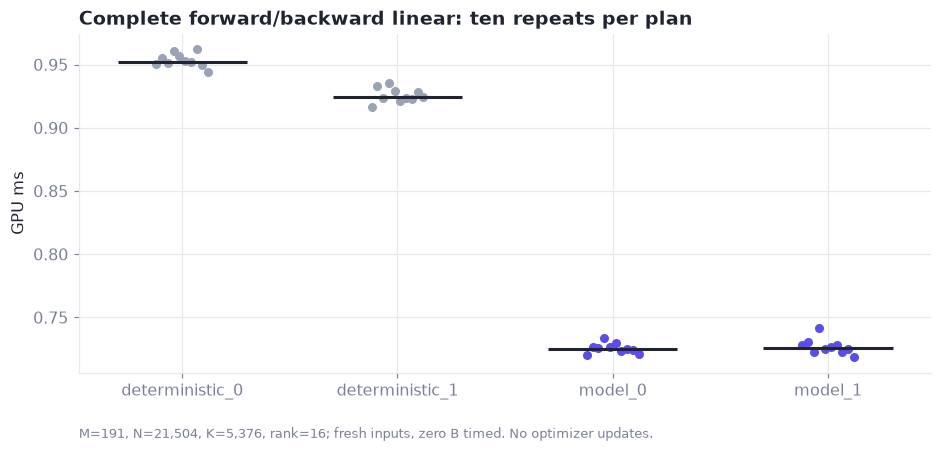

Latency reduction vs deterministic 1 in this run: 21.53%


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "xcalibur").is_dir():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import xcalibur as xc
from style import C, SEQ, MUTED, INK, DATA, save, note
import json
plans = pd.read_csv(DATA / "lora_operator.csv")
samples = pd.read_csv(DATA / "lora_operator_samples.csv")
medians = samples.groupby("plan")[["gpu_ms", "wall_ms"]].median()
assert len(plans) == 4 and len(samples) == 40
assert np.allclose(medians.loc[plans.plan, "gpu_ms"], plans.gpu_ms)
assert np.allclose(medians.loc[plans.plan, "wall_ms"], plans.wall_ms)
assert (plans.optimizer_updates == 0).all()
display(plans[["plan", "gpu_ms", "wall_ms", "reference_before_ms", "reference_after_ms", "qualified"]])
fig, ax = plt.subplots(figsize=(10, 4))
for i, label in enumerate(plans.plan):
    values = samples[samples.plan == label].gpu_ms.to_numpy()
    ax.scatter(np.full(len(values), i) + np.linspace(-.12, .12, len(values)), values,
               color=C["ours"] if label.startswith("model") else C["ref"], s=24)
    ax.hlines(np.median(values), i-.3, i+.3, color=INK, linewidth=2)
ax.set_xticks(range(len(plans)), plans.plan); ax.set_ylabel("GPU ms")
ax.set_title("Complete forward/backward linear: ten repeats per plan")
note(ax, "M=191, N=21,504, K=5,376, rank=16; fresh inputs, zero B timed. No optimizer updates.")
save(fig, "lora_operator_results"); plt.show()
reference = plans.set_index("plan").loc["deterministic_1", "gpu_ms"]
candidate = plans.set_index("plan").loc["model_0", "gpu_ms"]
print(f"Latency reduction vs deterministic 1 in this run: {100 * (1-candidate/reference):.2f}%")


The model plan retained decoded W and used supported CuTe epilogues; large
GEMMs remained library calls. Decoded W alone occupied 220.5 MiB. This four-plan
study does not establish whole-model fit or policy superiority.

## A resource counterexample the model could repair

The native plan requested two CTAs per SM with 174,848 shared bytes per CTA plus
1,024 auxiliary bytes. The recorded diagnostic rejected two CTAs, and the model
reduced residency to one. Recompute that diagnostic; native correctness comes
from the separate measured record, not this arithmetic.

In [2]:
per_cta, sm_capacity = 174848 + 1024, 233472
for ctas in [2, 1]:
    required = ctas * per_cta
    print(f"{ctas} CTA(s): {required:,} / {sm_capacity:,} bytes ->", "fits" if required <= sm_capacity else "reject")
assert 2 * per_cta > sm_capacity >= per_cta


2 CTA(s): 351,744 / 233,472 bytes -> reject
1 CTA(s): 175,872 / 233,472 bytes -> fits


## Execution succeeded; performance regressed

All six recorded loads passed numerical checks. The complete operator was slower than its parent. The intervals and A/A control remain attached to that outcome.

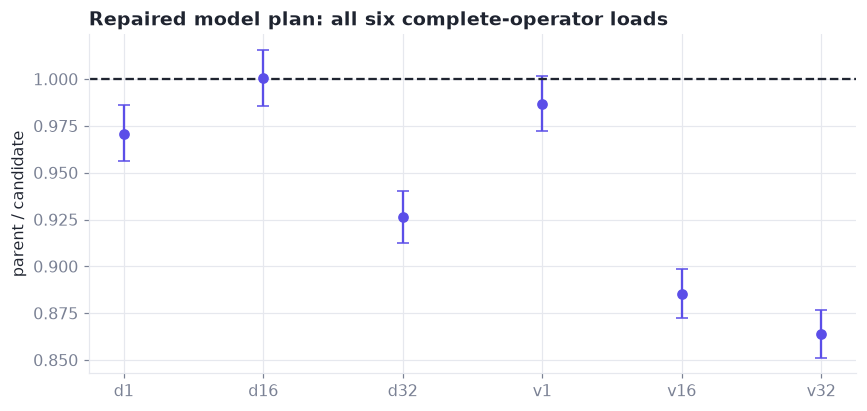

Geometric speedup: 0.93749; interval: [0.9236346208456707, 0.951551477260731]
A/A: 1.00002


,load,parent_us,candidate_us,ratio,interval_low,interval_high,checked_pairs,numerical_failures
0,d1,24.704000,25.488000,0.970516,0.956173,0.986191,4,0
1,d16,105.008002,104.784000,1.000604,0.985817,1.015614,4,0
2,d32,119.184002,128.528002,0.926173,0.912485,0.940125,4,0
3,v1,73.200002,74.928000,0.986722,0.972140,1.001523,4,0
4,v16,167.679999,188.751999,0.885472,0.872386,0.898754,4,0
5,v32,207.951996,241.231996,0.863915,0.851148,0.876874,4,0


In [3]:
loads = pd.read_csv(DATA / "model_tool_feedback.csv")
summary = json.loads((DATA / "model_tool_feedback.json").read_text())
assert len(loads) == 6 and (loads.numerical_failures == 0).all()
assert np.isclose(np.exp(np.log(loads.ratio).mean()), summary["geomean_speedup"])
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(loads.load, loads.ratio,
    yerr=np.array([loads.ratio-loads.interval_low, loads.interval_high-loads.ratio]),
    fmt="o", color=C["ours"], capsize=4)
ax.axhline(1, color=INK, ls="--"); ax.set_ylabel("parent / candidate")
ax.set_title("Repaired model plan: all six complete-operator loads")
save(fig, "model_tool_feedback"); plt.show()
print(f"Geometric speedup: {summary['geomean_speedup']:.5f}; interval: {summary['interval']}")
print(f"A/A: {summary['baseline_AA']:.5f}")
display(loads)


The CUDA-function route was a separate component experiment: unchanged model arithmetic passed after a wrapper repair, but was also slower than its control. The [write-up](../docs/studies.md#model-feedback) distinguishes that replay from the original live trajectory.

[Notebook guide](README.md) · [Documentation](../docs/README.md#reading-order) · [Data provenance](../data/README.md)